# SOLVE GAUSS' LAW WITH A PINN

In [45]:
from matplotlib import pyplot as plt
import numpy as np
import scipy
from numba import jit

In [2]:


eps0 = 1.
q = 100.

def calc_potential(x,y):
    r = np.sqrt(x**2. + y**2.)
    return (1/(4*np.pi*eps0))*(q/r)

x = np.linspace(1,3,20)
y = np.linspace(1,3,20)

Chi1 = x - 2.
Chi2 = y - 2.

training_data = np.zeros((len(x)*len(y),3))
idx = 0
for i in range(0, len(x)):
    for j in range(0, len(y)):
        training_data[idx, 0] = x[i] - 2
        training_data[idx, 1] = y[j] - 2
        training_data[idx, 2] = calc_potential(x[i], y[j])
        idx = idx + 1



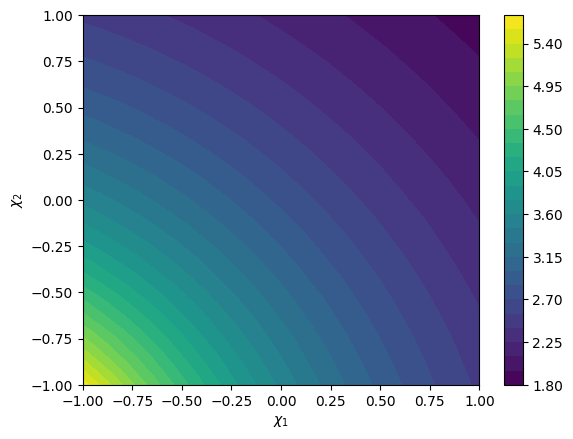

In [3]:
plt.tricontourf(training_data[:,0] ,training_data[:,1] ,training_data[:,2], levels=30,cmap='viridis')
plt.xlabel(r'$\chi_1$')
plt.ylabel(r'$\chi_2$')
plt.colorbar()
plt.show()

So my training data consists of more than just vanilla boundary data/initial data

## Network 


Use 1000 collocation points in addition to 400 training samples

n = 50 neurons in hidden layer

$\sigma(z) = tanh(z)$ activation function

In [144]:
#make collocation points

N_col = 1600

xcol = np.linspace(1,3,40)
ycol = np.linspace(1,3,40)

Chi1col = xcol - 2.
Chi2col = ycol - 2.

col_points = np.zeros((len(xcol)*len(ycol),2))
idx = 0
for i in range(0, len(xcol)):
    for j in range(0, len(ycol)):
        col_points[idx, 0] = Chi1col[i]
        col_points[idx, 1] = Chi2col[j]
        idx = idx + 1


In [145]:
#number of neurons in hidden layer

n = 50

In [170]:
#randomly assign weights and biases

w2 = np.random.uniform(-1, 1, (n))
b2 = np.random.uniform(-1,1)
w1 = np.random.uniform(-1, 1, (n,2))
b1 = np.random.uniform(-1, 1, (n))

w2_old = np.copy(w2)
b2_old = np.copy(b2)
w1_old = np.copy(w1)
b1_old = np.copy(b1)

In [171]:
#activation function

#@jit(nopython=True)
def sigma(z):
    return np.tanh(z)

#@jit(nopython=True)
def sigma1(z):
    return 1 - sigma(z)**2.

#@jit(nopython=True)
def sigma2(z):
    return -2*sigma(z)*(1 - sigma(z)**2.)

#@jit(nopython=True)
def sigma3(z):
    return -2*(1 - sigma(z)**2.)*(1 - 3*sigma(z)**2.)


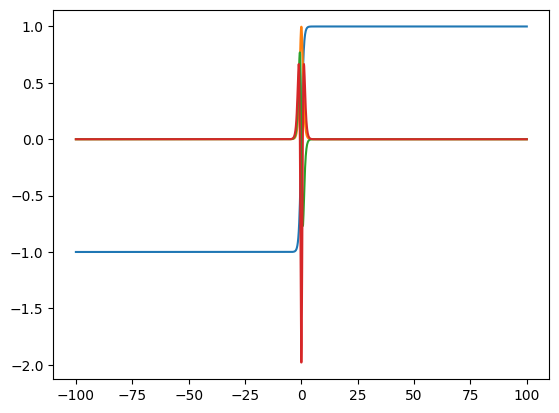

In [172]:
plt.plot(np.linspace(-100,100,2000), sigma(np.linspace(-100,100,2000)))
plt.plot(np.linspace(-100,100,2000), sigma1(np.linspace(-100,100,2000)))
plt.plot(np.linspace(-100,100,2000), sigma2(np.linspace(-100,100,2000)))
plt.plot(np.linspace(-100,100,2000), sigma3(np.linspace(-100,100,2000)))
plt.show()

In [173]:
#functions to calculate values of u and its derivatives

#@jit(nopython=True)
def u_forward_pass(Chi1, Chi2):
    z1 = w1@np.array([Chi1, Chi2]) + b1
    return w2@sigma(z1) + b2

#@jit(nopython=True)
def uChi1Chi1_forward_pass(Chi1, Chi2):
    z1 = w1@np.array([Chi1, Chi2]) + b1
    return w2@(sigma2(z1)*w1[:,0]**2.) 

#@jit(nopython=True)
def uChi2Chi2_forward_pass(Chi1, Chi2):
    z1 = w1@np.array([Chi1, Chi2]) + b1
    return w2@(sigma2(z1)*w1[:,1]**2.) 

$$ u_{xx} + u_{yy} + u_{zz}|_{z=0} = 0 $$

$$ u_{xx} + u_{yy} - \frac{q}{4 \pi \epsilon_0 (x^2 + y^2)^\frac{3}{2}} = 0$$

## Training and Movie

In [174]:
epochs = 10000
alpha = 1e-2

cost = np.zeros(epochs)



In [175]:
#find the first cost 

#@jit(nopython=True)
def find_cost():
    costm = 0.
    #training data part
    for m in range(0, len(training_data)):
        Chi1,Chi2 = training_data[m,0], training_data[m, 1]
        u = u_forward_pass(Chi1, Chi2)
        err = u - training_data[m, 2]

        costm = costm + (1/len(training_data))*err**2. 

    #PDE PINN part
    for m in range(0, len(col_points)):
        Chi1, Chi2 = col_points[m,0], col_points[m,1]
        u_Chi1Chi1 = uChi1Chi1_forward_pass(Chi1, Chi2)
        u_Chi2Chi2 = uChi2Chi2_forward_pass(Chi1, Chi2)
        err = u_Chi1Chi1 + u_Chi2Chi2 - (q/(4*np.pi*eps0*((Chi1+2)**2. + (Chi2+2)**2.)**(1.5)))

        costm = costm + (1/len(col_points))*err**2.

    return costm

cost[0] = find_cost()

In [176]:
from matplotlib.animation import PillowWriter

In [177]:
metadata = dict(title='Movie', artist ='ayush_roy')
writer = PillowWriter(fps=10, metadata = metadata)

In [178]:
#@jit(nopython=True)
def set_weights_and_biases():
    global b2,w2,b1,w1
    #slopes for given epoch
    slope_b2  = 0.
    slope_w2 = 0.
    slope_b1 = 0.
    slope_w1 = 0.

    #training data part
    for m in range(0, len(training_data)):
        Chi1,Chi2 = training_data[m,0], training_data[m, 1]
        u = u_forward_pass(Chi1, Chi2)
        z1 = w1@np.array([Chi1, Chi2]) + b1
        err = (1/len(training_data))*(u - training_data[m, 2])

        slope_b2 = slope_b2 + 2*(err)
        slope_w2 = slope_w2 + 2*(err)*sigma(z1)
        slope_b1 = slope_b1 + 2*(err)*w2*sigma1(z1)
        temp = np.zeros((n, 2))
        temp[:,0] = 2*(err)*w2*sigma1(z1)*Chi1
        temp[:,1] = 2*(err)*w2*sigma1(z1)*Chi2
        slope_w1 = slope_w1 + temp


    #PDE/PINN part
    for m in range(0, len(col_points)):
        Chi1, Chi2 = col_points[m,0], col_points[m,1]
        u_Chi1Chi1 = uChi1Chi1_forward_pass(Chi1, Chi2)
        u_Chi2Chi2 = uChi2Chi2_forward_pass(Chi1, Chi2)
        z1 = w1@np.array([Chi1, Chi2]) + b1
        err = (1/len(col_points))*(u_Chi1Chi1 + u_Chi2Chi2 - (q/(4*np.pi*eps0*((Chi1+2)**2. + (Chi2+2)**2.)**(1.5))))

        #slope_b2 gets no contribution from PDE 
        slope_w2 = slope_w2 + 2*err*sigma2(z1)*(w1[:,0]**2. + w1[:,1]**2.)
        slope_b1 = slope_b1 + 2*err*w2*sigma3(z1)*(w1[:,0]**2. + w1[:,1]**2.)
        temp = np.zeros((n, 2))
        temp[:,0] = 2*err*(w2*sigma3(z1)*(w1[:,0]**2 + w1[:,1]**2.)*Chi1 + w2*sigma2(z1)*2*w1[:,0] )
        temp[:,1] = 2*err*(w2*sigma3(z1)*(w1[:,0]**2 + w1[:,1]**2.)*Chi2 + w2*sigma2(z1)*2*w1[:,1] )
        slope_w1 = slope_w1 + temp

  
    #update weights and biases
    b2 = b2 - alpha*slope_b2
    w2 = w2 - alpha*slope_w2
    b1 = b1 - alpha*slope_b1
    w1 = w1 - alpha*slope_w1
    

    '''
    if cost[t] < cost[t-1]:
        alpha = alpha* 1.1
        b2_old = np.copy(b2)
        w2_old = np.copy(w2)
        b1_old = np.copy(b1)
        w1_old = np.copy(w1)
    else:
        b2, w2, b1, w1 = np.copy(b2_old), np.copy(w2_old), np.copy(b1_old), np.copy(w1_old)
        alpha = alpha*0.5
        cost[t] = cost[t-1]
    '''

  



In [179]:
#@jit(nopython=True)
def build_visualize_network_data():
    visualize_data = np.zeros((len(x)*len(y),3))
    idx = 0
    for i in range(0, len(x)):
        for j in range(0, len(y)):
            visualize_data[idx, 0] = x[i] 
            visualize_data[idx, 1] = y[j] 
            visualize_data[idx, 2] = u_forward_pass(x[i]-2, y[j]-2)
            idx = idx + 1
    return visualize_data

In [180]:
def plot_frame(index,ax):
    network_data = build_visualize_network_data()

    pinn_visual = ax[0]
    cost_visual = ax[1]

    pinn_visual.tricontourf(network_data[:,0] ,network_data[:,1] ,network_data[:,2], levels=30,cmap='viridis')
    pinn_visual.set_xlabel(r'$x$', fontsize=20, c='white')
    pinn_visual.set_ylabel(r'$y$', fontsize=20, c='white')
    pinn_visual.tick_params(colors='white')
    #pinn_visual.add_colorbar()

    #####################################################################################
    cost_visual.semilogy( np.arange(1,index+2), cost[0:index+1], c='red')
    cost_visual.set_xlabel('Epoch', c='white', fontsize=20)
    cost_visual.set_ylabel('Loss Function', c='white', fontsize=20)
    cost_visual.tick_params(colors='white')
    cost_visual.set_xlim([0,10001])
    cost_visual.set_ylim([1e-6,1e2])
    


    

1 14.918649427917357
2 7.1330010396392565
3 4.561021299777506
4 3.5021268537174763
5 2.930723887045975
6 2.546586303370179
7 2.2542523595824804
8 2.018541134983045
9 1.8233481267944578
10 1.6594337388833638
11 1.5205501916043216
12 1.40206160786282
13 1.3003613123181506
14 1.2125734959026837
15 1.1363730859956316
16 1.0698639534309904
17 1.0114906322309398
18 0.959971570728224
19 0.9142472986351066
20 0.8734394593788716
21 0.8368180341113702
22 0.8037748933517029
23 0.7738023222413558
24 0.7464755047255488
25 0.7214381880308847
26 0.6983909191706257
27 0.6770813719022615
28 0.6572963790616471
29 0.6388553600832216
30 0.6216048924626021
31 0.6054142228211505
32 0.5901715508555889
33 0.5757809498201155
34 0.5621598118071877
35 0.5492367261238731
36 0.5369497154032177
37 0.525244767452077
38 0.5140746117812095
39 0.5033976987397584
40 0.4931773465479301
80 0.2743562521583824
120 0.19522439235669692
160 0.156295273200011
200 0.13316185908618453
240 0.11754817651575568
280 0.106110160332893

IndexError: index 10000 is out of bounds for axis 0 with size 10000

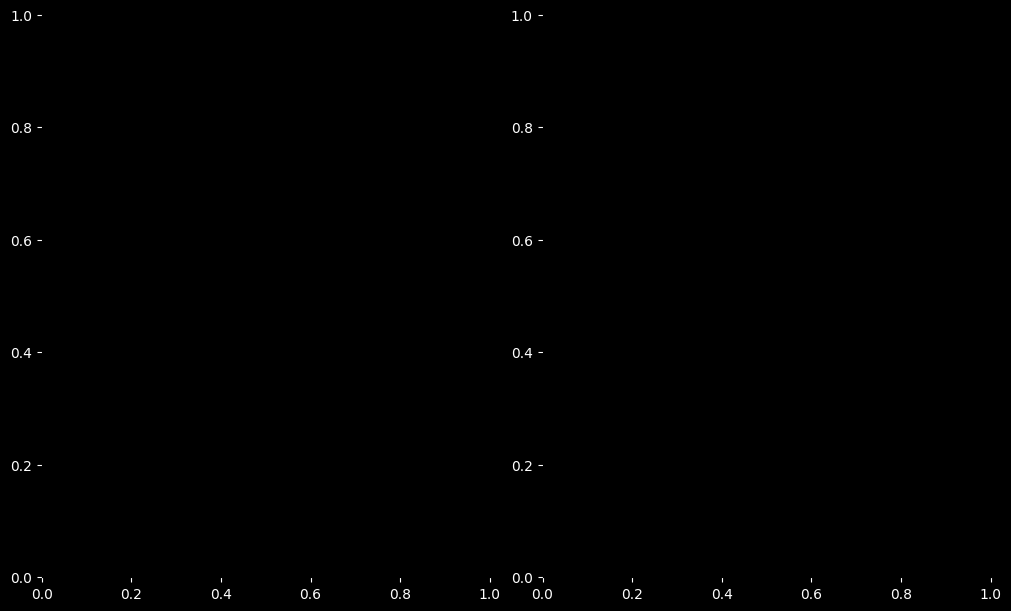

In [ ]:
fig, ax = plt.subplots(1,2, figsize=(10, 6), constrained_layout=True)
fig.patch.set_facecolor('black')
ax[0].set_facecolor('black')
ax[1].set_facecolor('black')

with writer.saving(fig, 'electrostatics_pinn.gif',100):
    for i in range(1, epochs):
        set_weights_and_biases()
        cost[i] = find_cost()
        if i%40 == 0 or 1<=i<=40 or i==epochs:
            print(i,cost[i])
            plot_frame(i,ax)
            ax[0].set_title(r'$\nabla^2 \psi|_{z=0} = 0, \quad \psi \propto \frac{1}{\sqrt{x^2 + y^2}}$ ',c='white', fontsize = 20)
            ax[1].set_title('Epoch: '+str(i), c='white', fontsize = 20)
            writer.grab_frame()
            ax[0].clear()
            ax[1].clear()

In [186]:
calc_potential(1,1)

5.626976975981912

In [185]:
u_forward_pass(-1,-1)

5.23945845676831